In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [3]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nFirst 5 Rows:")
print(df.head())

Dataset Shape: (100000, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None

First 5 Rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No I

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [6]:
df = df.dropna()

print("Missing values removed")
print("New Dataset Shape:", df.shape)

Missing values removed
New Dataset Shape: (100000, 9)


In [7]:
df = pd.get_dummies(
    df,
    columns=['gender', 'smoking_history'],
    drop_first=True,
    dtype=int
)

print(df.head())

    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   diabetes  gender_Male  gender_Other  smoking_history_current  \
0         0            0             0                        0   
1         0            0             0                        0   
2         0            1             0                        0   
3         0            0             0                        1   
4         0            1             0                        1   

   smoking_history_ever  smoking_history_former  smoking_history_never  \
0                     0             

In [8]:
X = df.drop('diabetes', axis=1)

y = df['diabetes']

print("Input Data:")
print(X.head())

print("\nOutput Data:")
print(y.head())

Input Data:
    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   gender_Male  gender_Other  smoking_history_current  smoking_history_ever  \
0            0             0                        0                     0   
1            0             0                        0                     0   
2            1             0                        0                     0   
3            0             0                        1                     0   
4            1             0                        1                     0   

   smoking_history_former 

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (80000, 13)
Testing Data: (20000, 13)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [11]:
svm_model = LinearSVC(
    max_iter=5000,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM Model Trained Successfully")

SVM Model Trained Successfully


In [12]:
y_pred = svm_model.predict(X_test_scaled)

print("Predicted Values:")
print(y_pred[:10])

Predicted Values:
[0 0 0 0 0 0 0 1 0 1]


In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy * 100, "%")

SVM Accuracy: 96.035 %


In [14]:
print("Classification Report:")

print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.88      0.61      0.72      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.80      0.85     20000
weighted avg       0.96      0.96      0.96     20000



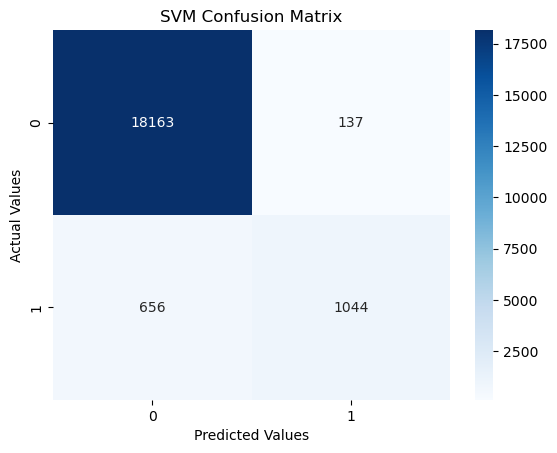

In [15]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("SVM Confusion Matrix")

plt.show()

In [16]:
print("Support Vector Machine Results")
print("--------------------------------")

print("Training Accuracy:",
      svm_model.score(X_train_scaled, y_train) * 100, "%")

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred) * 100, "%")

print("Model Execution Completed Successfully")

Support Vector Machine Results
--------------------------------
Training Accuracy: 96.07875 %
Testing Accuracy: 96.035 %
Model Execution Completed Successfully
